# Tarea 1 · Parte 1: Recolección de noticias

| | |
|---|---|
| **Fecha de descarga** | 18 de octubre de 2026 (hora de Lima, UTC−5) |
| **Medio elegido** | **Opción A: La República** (Perú) |
| **URL base** | https://larepublica.pe |
| **robots.txt** | https://larepublica.pe/robots.txt |
| **RSS oficiales** | https://larepublica.pe/rss/politica.xml · https://larepublica.pe/rss/economia.xml · https://larepublica.pe/rss/deportes.xml · https://larepublica.pe/rss/ciencia.xml · https://larepublica.pe/rss/home.xml · (probado: https://larepublica.pe/rss/tecnologia.xml) |
| **Portadas de sección** | https://larepublica.pe/politica · /economia · /deportes · /ciencia · /tecnologia |
| **Páginas de artículo** | `https://larepublica.pe/<seccion>/AAAA/MM/DD/<slug>-<id>` |

**Objetivo:** construir un corpus de al menos 350 noticias reales (meta: unas 100 por categoría) con las columnas
`titular, bajada, medio, seccion_original, url, fecha`, limpiarlo, asignarle una de 4 etiquetas fijas
(`politica`, `economia`, `deportes`, `ciencia_tecnologia`) y exportarlo a `datos/noticias.csv`.

## 0. Estrategia y reglas de recolección responsable

1. **Revisar `robots.txt`** y comprobar *cada* URL antes de pedirla (el parser estándar de Python no entiende comodines `*`, así que se implementa uno propio con la regla de *coincidencia más larga*).
2. **RSS oficiales primero.** Cada feed de sección trae solo ~10–16 notas de las últimas 48 h y `home.xml` unas 195 de todas las secciones. Es insuficiente para ~100 por categoría.
3. **Complemento con `requests` + `BeautifulSoup`:** cada página de artículo enlaza a otras notas de su misma sección. Se hace un recorrido en anchura (BFS), **de lo más reciente a lo más antiguo**, empezando por los enlaces del RSS y de las portadas de sección, hasta juntar unas 100 notas por grupo de secciones.
   No se usa la paginación de secciones porque robots.txt la prohíbe (`Disallow: /*/pag/*`), ni las páginas de etiquetas (`/tag/`), ni `/envivo/` ni `/amp/`.
4. **Cortesía:** `User-Agent` descriptivo, pausa aleatoria de **1 a 2 s antes de cada solicitud**, *timeout* de 20 s y **máximo 1 reintento**.
5. **Respaldo crudo** en `datos/raw/`: `robots.txt`, los XML de cada RSS, `noticias_crudas.csv` (todos los registros antes de limpiar) y `metadatos_descarga.json`.

In [1]:
import heapq
import json
import random
import re
import time
from collections import Counter
from datetime import datetime
from pathlib import Path
from urllib.parse import urlsplit
from xml.etree import ElementTree as ET

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup

BASE = "https://larepublica.pe"
MEDIO = "La República"
USER_AGENT = ("TareaPythonIntermedio/1.0 (proyecto academico individual del curso Python Intermedio; "
              "recoleccion de titulares para clasificacion; python-requests)")
PAUSA_MIN, PAUSA_MAX = 1.0, 2.0   # segundos entre solicitudes
MAX_REINTENTOS = 1
TIMEOUT = 20

DATOS = Path("datos")
RAW = DATOS / "raw"
RAW.mkdir(parents=True, exist_ok=True)
ARCHIVO_CRUDO = RAW / "noticias_crudas.csv"

# Si ya existe un respaldo crudo se reutiliza: el notebook se puede re-ejecutar
# sin volver a descargar nada y los resultados no cambian.
REUTILIZAR_RESPALDO = True

# Plotly se guarda como imagen PNG para que los gráficos se vean en GitHub
pio.renderers.default = "png"
pio.templates.default = "simple_white"
COLORES = {"politica": "#2a78d6", "economia": "#eb6834",
           "deportes": "#1baf7a", "ciencia_tecnologia": "#eda100"}
ORDEN_CATEGORIAS = list(COLORES)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
random.seed(2026)
print("Fecha/hora de ejecución:", datetime.now().strftime("%Y-%m-%d %H:%M"))

Fecha/hora de ejecución: 2026-10-18 01:28


## 1. `robots.txt`: lectura y verificación

Las reglas aplican a `User-agent: *` (el archivo agrupa a todos los agentes en un solo bloque).

In [2]:
sesion = requests.Session()
sesion.headers.update({"User-Agent": USER_AGENT, "Accept-Language": "es-PE,es;q=0.9"})
registro = Counter()   # contador de solicitudes por resultado


def pedir(url, forzar=False):
    # GET con pausa de 1-2 s, timeout y como máximo 1 reintento.
    # Devuelve la respuesta (aunque sea 4xx) o None si falló la conexión.
    if not forzar and not permitido(url):
        registro["bloqueada_por_robots"] += 1
        return None
    for intento in range(1 + MAX_REINTENTOS):
        time.sleep(random.uniform(PAUSA_MIN, PAUSA_MAX))
        try:
            r = sesion.get(url, timeout=TIMEOUT)
            if r.status_code >= 500 and intento < MAX_REINTENTOS:
                registro["reintento"] += 1
                continue
            registro[f"http_{r.status_code}"] += 1
            return r
        except requests.RequestException as e:
            if intento < MAX_REINTENTOS:
                registro["reintento"] += 1
                continue
            registro["error_conexion"] += 1
            print("  ✗", url, type(e).__name__)
            return None


def leer_reglas(texto):
    # Reglas Allow/Disallow del bloque que incluye User-agent: *
    reglas, en_bloque, leyendo_agentes = [], False, False
    for linea in texto.splitlines():
        linea = linea.split("#", 1)[0].strip()
        if not linea or ":" not in linea:
            continue
        campo, valor = (p.strip() for p in linea.split(":", 1))
        campo = campo.lower()
        if campo == "user-agent":
            if not leyendo_agentes:
                en_bloque = False
            leyendo_agentes = True
            en_bloque = en_bloque or valor == "*"
            continue
        leyendo_agentes = False
        if en_bloque and campo in ("allow", "disallow") and valor:
            patron = re.escape(valor).replace(r"\*", ".*")
            if patron.endswith(r"\$"):
                patron = patron[:-2] + "$"
            if not valor.startswith(("/", "*")):
                patron = ".*" + patron      # reglas como '*/sitemaps/*'
            reglas.append((campo == "allow", len(valor), re.compile(patron), valor))
    return reglas


def permitido(url):
    # Regla de coincidencia más larga; Allow gana en empate (criterio RFC 9309)
    partes = urlsplit(url)
    ruta = partes.path + ("?" + partes.query if partes.query else "")
    coincidencias = [(largo, allow) for allow, largo, rx, _ in REGLAS if rx.match(ruta)]
    if not coincidencias:
        return True
    return max(coincidencias)[1]


r = pedir(f"{BASE}/robots.txt", forzar=True)
texto_robots = r.content.decode("utf-8")
(RAW / "robots.txt").write_text(texto_robots, encoding="utf-8")
REGLAS = leer_reglas(texto_robots)
print(f"robots.txt: HTTP {r.status_code}, {len(REGLAS)} reglas para User-agent: *")
print("Disallow:", [v for a, _, _, v in REGLAS if not a])
print("Allow:   ", [v for a, _, _, v in REGLAS if a])

robots.txt: HTTP 200, 27 reglas para User-agent: *
Disallow: ['/buscador*', '/data', '/data/*', '/contactenos', '/*/pag/', '/*/pag/*', '/*/*/page/*', '/archive/*', '/archivo/*', '/node/*', '/taxonomy/term/*', '/assets/*', '/files/*', '/comment/reply/*', '/envivo/*', '/*/tag/*', '*/*Perú', '*/Encuesta*', '*/EMPRESA/*', '*ref=photogallery*', '*/sitemaps/*', '*/pf/*']
Allow:    ['/sitemap/', '/sitemap/*', '/sitemaps/*', '/rss/', '/rss/*']


In [3]:
pruebas = [
    f"{BASE}/rss/politica.xml",
    f"{BASE}/politica",
    f"{BASE}/politica/2026/10/17/comision-de-constitucion-aun-no-convoca-a-sesion-para-debatir-pedido-de-facultades-hnews-696677",
    f"{BASE}/politica/pag/2",          # paginación de sección
    f"{BASE}/politica/tag/congreso",   # etiquetas dentro de sección
    f"{BASE}/buscador?q=economia",
    f"{BASE}/envivo/123",
    f"{BASE}/archivo/2026",
]
pd.DataFrame({"url": pruebas, "permitido": [permitido(u) for u in pruebas]})

,url,permitido
0,https://larepublica.pe/rss/politica.xml,True
1,https://larepublica.pe/politica,True
2,https://larepublica.pe/politica/2026/10/17/comision-de-constitucion-aun-no-convoca-a-sesion-para-debatir-pedido-de-f...,True
3,https://larepublica.pe/politica/pag/2,False
4,https://larepublica.pe/politica/tag/congreso,False
5,https://larepublica.pe/buscador?q=economia,False
6,https://larepublica.pe/envivo/123,False
7,https://larepublica.pe/archivo/2026,False


**Conclusión:** los RSS, las portadas de sección y las páginas de artículo están permitidos; la paginación,
el buscador, el archivo y `/envivo/` están prohibidos, por lo que el recorrido **no** los usa.

## 2. Recolección

### 2.1 RSS oficiales

> **Nota de transparencia sobre la ejecución:** la descarga real se hizo el 18/10/2026 entre las 01:11 y las 01:27 (hora de Lima). Las salidas de las celdas de recolección (2.1 RSS, 2.2 recorrido y 2.3 respaldo) son las de **esa descarga original**. Luego el notebook se volvió a ejecutar completo para ajustar los gráficos del EDA. Esa segunda ejecución **no descargó nada**: con `REUTILIZAR_RESPALDO = True` leyó el respaldo de `datos/raw/noticias_crudas.csv`, así que la limpieza, el EDA y la exportación se calcularon sobre exactamente los mismos datos. El código de las celdas de recolección no cambió entre ambas ejecuciones.

In [4]:
FEEDS = ["politica", "economia", "deportes", "ciencia", "tecnologia", "home"]
PATRON_ARTICULO = re.compile(
    r"(?:https://larepublica\.pe)?(/(?!amp/)[a-z0-9-]+(?:/[a-z0-9-]+)*/20\d\d/\d\d/\d\d/[a-z0-9-]+-\d{4,})")


def seccion_de(url):
    # Primer segmento de la ruta: así nombra el propio medio a la sección
    return urlsplit(url).path.strip("/").split("/")[0]


def limpiar_texto(t):
    if t is None:
        return ""
    t = BeautifulSoup(t, "html.parser").get_text(" ")
    return re.sub(r"\s+", " ", t).strip()


def leer_rss(xml_bytes, feed):
    filas = []
    for item in ET.fromstring(xml_bytes).iter("item"):
        url = (item.findtext("link") or "").strip()
        filas.append({
            "titular": limpiar_texto(item.findtext("title")),
            "bajada": limpiar_texto(item.findtext("description")),
            "medio": MEDIO,
            "seccion_original": seccion_de(url),
            "url": url,
            "fecha": (item.findtext("pubDate") or "").strip(),
            "categoria_rss": (item.findtext("category") or "").strip(),
            "fuente": f"rss:{feed}",
        })
    return filas


usar_respaldo = REUTILIZAR_RESPALDO and ARCHIVO_CRUDO.exists()
estado_feeds = []
filas_rss = []
if usar_respaldo:
    print(f"Se reutiliza el respaldo existente {ARCHIVO_CRUDO} (no se descarga nada).")
else:
    for feed in FEEDS:
        url = f"{BASE}/rss/{feed}.xml"
        r = pedir(url)
        n = 0
        if r is not None and r.status_code == 200:
            (RAW / f"rss_{feed}.xml").write_bytes(r.content)
            filas = leer_rss(r.content, feed)
            filas_rss += filas
            n = len(filas)
        estado_feeds.append({"feed": url, "http": None if r is None else r.status_code, "items": n})
    display(pd.DataFrame(estado_feeds))
    print("Total de ítems RSS:", len(filas_rss))

,feed,http,items
0,https://larepublica.pe/rss/politica.xml,200,16
1,https://larepublica.pe/rss/economia.xml,200,9
2,https://larepublica.pe/rss/deportes.xml,200,9
3,https://larepublica.pe/rss/ciencia.xml,200,10
4,https://larepublica.pe/rss/tecnologia.xml,410,0
5,https://larepublica.pe/rss/home.xml,200,194


Total de ítems RSS: 238


> **Documentación de bloqueos:** `rss/tecnologia.xml` responde **HTTP 410 (Gone)**: el medio retiró ese feed
> (robots.txt tampoco lo lista). Las notas de tecnología se obtienen desde la portada `/tecnologia` y desde los
> enlaces internos de los artículos. Ningún otro recurso usado fue bloqueado.

### 2.2 Complemento: portadas de sección + recorrido por artículos (`requests` + `BeautifulSoup`)

Los grupos de rastreo solo sirven para decidir **qué enlaces seguir** y cuándo parar (cuota de 100 notas por grupo);
la asignación formal de etiquetas se hace y se documenta en la sección 3.

In [5]:
GRUPOS_RASTREO = {
    "politica": ["politica"],
    "economia": ["economia"],
    "deportes": ["deportes", "futbol-peruano"],
    "ciencia_tecnologia": ["ciencia", "tecnologia"],
}
CUOTA_POR_GRUPO = 100
GRUPO_DE = {sec: g for g, secs in GRUPOS_RASTREO.items() for sec in secs}


def fecha_en_url(ruta):
    m = re.search(r"/(20\d\d)/(\d\d)/(\d\d)/", ruta)
    return int("".join(m.groups())) if m else 0


def parsear_articulo(html, url):
    sopa = BeautifulSoup(html, "html.parser")
    meta = lambda **kw: (sopa.find("meta", attrs=kw) or {}).get("content", "")
    h1 = sopa.find("h1")
    titular = limpiar_texto(h1.get_text(" ")) if h1 else limpiar_texto(meta(property="og:title"))
    bajada = limpiar_texto(meta(property="og:description") or meta(name="description"))
    fecha, seccion_jsonld = "", ""
    for s in sopa.find_all("script", type="application/ld+json"):
        try:
            datos = json.loads(s.string or "")
        except json.JSONDecodeError:
            continue
        for obj in datos if isinstance(datos, list) else [datos]:
            if isinstance(obj, dict) and "NewsArticle" in str(obj.get("@type", "")):
                fecha = obj.get("datePublished", fecha)
                seccion_jsonld = obj.get("articleSection", seccion_jsonld)
    if not fecha:
        fecha = meta(property="article:published_time")
    return {"titular": titular, "bajada": bajada, "medio": MEDIO,
            "seccion_original": seccion_de(url), "url": url, "fecha": fecha,
            "categoria_rss": seccion_jsonld, "fuente": "articulo"}


def enlaces_articulo(html):
    return {m for m in PATRON_ARTICULO.findall(html)}


filas_articulos = []
if not usar_respaldo:
    inicio = time.time()
    cola, vistos = [], set()

    def encolar(ruta):
        ruta = ruta.split("?")[0].rstrip("/")
        if ruta in vistos or seccion_de(ruta) not in GRUPO_DE:
            return
        if not permitido(BASE + ruta):
            registro["enlace_descartado_por_robots"] += 1
            return
        vistos.add(ruta)
        heapq.heappush(cola, (-fecha_en_url(ruta), ruta))   # más recientes primero

    # Semillas: enlaces del RSS + portadas de sección
    for f in filas_rss:
        encolar(urlsplit(f["url"]).path)
    for sec in GRUPO_DE:
        if sec == "futbol-peruano":
            continue
        r = pedir(f"{BASE}/{sec}")
        if r is not None and r.status_code == 200:
            for ruta in enlaces_articulo(r.content.decode("utf-8", "replace")):
                encolar(ruta)
    print(f"Semillas en cola: {len(cola)}")

    obtenidas = Counter()
    while cola and min(obtenidas[g] for g in GRUPOS_RASTREO) < CUOTA_POR_GRUPO:
        _, ruta = heapq.heappop(cola)
        grupo = GRUPO_DE[seccion_de(ruta)]
        if obtenidas[grupo] >= CUOTA_POR_GRUPO:
            continue
        r = pedir(BASE + ruta)
        if r is None or r.status_code != 200:
            continue
        html = r.content.decode("utf-8", "replace")
        filas_articulos.append(parsear_articulo(html, BASE + ruta))
        obtenidas[grupo] += 1
        for enlace in enlaces_articulo(html):
            encolar(enlace)
        if len(filas_articulos) % 50 == 0:
            print(f"  {len(filas_articulos):>3} artículos | {dict(obtenidas)} | "
                  f"cola={len(cola)} | {time.time() - inicio:.0f} s")

    print(f"\nArtículos descargados: {len(filas_articulos)} en {(time.time() - inicio) / 60:.1f} min")
    print("Por grupo:", dict(obtenidas))
    print("Registro de solicitudes:", dict(registro))

Semillas en cola: 64


   50 artículos | {'ciencia_tecnologia': 11, 'deportes': 14, 'economia': 11, 'politica': 14} | cola=226 | 130 s


  100 artículos | {'ciencia_tecnologia': 18, 'deportes': 25, 'economia': 19, 'politica': 38} | cola=337 | 241 s


  150 artículos | {'ciencia_tecnologia': 31, 'deportes': 39, 'economia': 28, 'politica': 52} | cola=469 | 351 s


  200 artículos | {'ciencia_tecnologia': 35, 'deportes': 54, 'economia': 34, 'politica': 77} | cola=527 | 465 s


  250 artículos | {'ciencia_tecnologia': 42, 'deportes': 66, 'economia': 44, 'politica': 98} | cola=589 | 577 s


  300 artículos | {'ciencia_tecnologia': 57, 'deportes': 88, 'economia': 55, 'politica': 100} | cola=614 | 690 s


  350 artículos | {'ciencia_tecnologia': 81, 'deportes': 100, 'economia': 69, 'politica': 100} | cola=627 | 810 s


  400 artículos | {'ciencia_tecnologia': 100, 'deportes': 100, 'economia': 100, 'politica': 100} | cola=662 | 925 s

Artículos descargados: 400 en 15.4 min
Por grupo: {'ciencia_tecnologia': 100, 'deportes': 100, 'economia': 100, 'politica': 100}
Registro de solicitudes: {'http_200': 411, 'http_410': 1, 'http_404': 7}


### 2.3 Respaldo crudo

In [6]:
if usar_respaldo:
    df_raw = pd.read_csv(ARCHIVO_CRUDO, keep_default_na=False)
else:
    df_raw = pd.DataFrame(filas_rss + filas_articulos)
    df_raw.to_csv(ARCHIVO_CRUDO, index=False, encoding="utf-8")
    metadatos = {
        "medio": MEDIO, "url_base": BASE,
        "fecha_descarga": datetime.now().isoformat(timespec="seconds"),
        "user_agent": USER_AGENT, "pausa_segundos": [PAUSA_MIN, PAUSA_MAX],
        "max_reintentos": MAX_REINTENTOS, "feeds": estado_feeds,
        "cuota_por_grupo": CUOTA_POR_GRUPO, "solicitudes": dict(registro),
        "registros_crudos": len(df_raw),
    }
    (RAW / "metadatos_descarga.json").write_text(json.dumps(metadatos, ensure_ascii=False, indent=2),
                                                 encoding="utf-8")

print("Registros crudos:", df_raw.shape)
print(df_raw["fuente"].value_counts().to_string())
print("\nArchivos en datos/raw/:")
for p in sorted(RAW.iterdir()):
    print(f"  {p.name:<28} {p.stat().st_size / 1024:>8.1f} KB")

Registros crudos: (638, 8)
fuente
articulo        400
rss:home        194
rss:politica     16
rss:ciencia      10
rss:economia      9
rss:deportes      9

Archivos en datos/raw/:
  .gitkeep                          0.0 KB
  metadatos_descarga.json           1.2 KB
  noticias_crudas.csv             333.0 KB
  robots.txt                        3.9 KB
  rss_ciencia.xml                  80.8 KB
  rss_deportes.xml                 59.3 KB
  rss_economia.xml                 62.3 KB
  rss_home.xml                   1278.6 KB
  rss_politica.xml                131.0 KB


## 3. Limpieza

Pasos, en este orden:
1. Normalizar espacios y URL (sin parámetros ni `/` final).
2. Eliminar titulares vacíos.
3. Eliminar duplicados por URL (la misma nota aparece en el RSS de su sección, en `home.xml` y en el recorrido). Se conserva primero la versión del RSS oficial.
4. Mapear `seccion_original` a las 4 categorías fijas y **descartar** lo que no encaja (no se crea una quinta categoría).

In [7]:
df = df_raw.copy()
for col in ["titular", "bajada", "seccion_original", "url", "fecha"]:
    df[col] = df[col].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["url"] = df["url"].str.split("?").str[0].str.rstrip("/")

descartes = []
n0 = len(df)

vacios = df["titular"].eq("")
descartes.append({"motivo": "Titular vacío", "cantidad": int(vacios.sum())})
df = df[~vacios]

df["prioridad"] = df["fuente"].str.startswith("rss").map({True: 0, False: 1})
df = df.sort_values(["prioridad", "fuente"])
dup = df.duplicated("url", keep="first")
descartes.append({"motivo": "URL duplicada (misma nota en varios feeds o en el recorrido)",
                  "cantidad": int(dup.sum())})
df = df[~dup].drop(columns="prioridad")

print(f"Registros crudos: {n0} → tras quitar vacíos y duplicados: {len(df)}")

Registros crudos: 638 → tras quitar vacíos y duplicados: 551


### 3.1 Tabla de equivalencias `seccion_original` → `etiqueta`

Criterio: `seccion_original` es el primer segmento de la URL, que es como el propio medio organiza sus secciones.

| seccion_original | etiqueta | justificación |
|---|---|---|
| `politica` | `politica` | Sección de política nacional |
| `economia` (incluye `economia/precio-del-dolar`) | `economia` | Sección de economía |
| `deportes`, `futbol-peruano` | `deportes` | Fútbol peruano es una subsección deportiva publicada fuera de `/deportes` |
| `ciencia`, `tecnologia` | `ciencia_tecnologia` | Las dos secciones que cubren ciencia y tecnología |
| `sociedad`, `mundo`, `espectaculos`, `latinos-en-usa`, `opinion`, `verificador`, `cultural`, `cine-series`, `entretenimiento`, `servicios`, `horoscopo`, `carlincatura`, ... | *(descartada)* | Mezclan temas o no corresponden a ninguna de las 4 categorías. `opinion` y `verificador` pueden tratar política, pero clasificarlas exigiría leer cada nota y se excluyen para no meter ruido en las etiquetas |

In [8]:
MAPEO = {
    "politica": "politica",
    "economia": "economia",
    "deportes": "deportes",
    "futbol-peruano": "deportes",
    "ciencia": "ciencia_tecnologia",
    "tecnologia": "ciencia_tecnologia",
}
df["etiqueta"] = df["seccion_original"].map(MAPEO)

tabla_equivalencias = (df.groupby("seccion_original", dropna=False).size().rename("noticias")
                         .reset_index()
                         .assign(etiqueta=lambda t: t["seccion_original"].map(MAPEO).fillna("— descartada —"))
                         .sort_values(["etiqueta", "noticias"], ascending=[True, False])
                         [["seccion_original", "etiqueta", "noticias"]]
                         .reset_index(drop=True))
tabla_equivalencias

,seccion_original,etiqueta,noticias
0,ciencia,ciencia_tecnologia,100
1,deportes,deportes,100
2,economia,economia,100
3,politica,politica,101
4,sociedad,— descartada —,51
5,espectaculos,— descartada —,28
6,mundo,— descartada —,20
7,latinos-en-usa,— descartada —,15
8,cine-series,— descartada —,5
9,cultural,— descartada —,5


In [9]:
fuera = df["etiqueta"].isna()
detalle_fuera = df.loc[fuera, "seccion_original"].value_counts()
descartes.append({"motivo": "Sección fuera de las 4 categorías: " +
                  ", ".join(f"{s} ({n})" for s, n in detalle_fuera.items()),
                  "cantidad": int(fuera.sum())})
df = df[~fuera].copy()

tabla_descartes = pd.DataFrame(descartes)
total_desc = tabla_descartes["cantidad"].sum()
display(tabla_descartes)
print(f"Total descartadas: {total_desc} de {n0} registros crudos → quedan {len(df)} noticias")

,motivo,cantidad
0,Titular vacío,0
1,URL duplicada (misma nota en varios feeds o en el recorrido),87
2,"Sección fuera de las 4 categorías: sociedad (51), espectaculos (28), mundo (20), latinos-en-usa (15), cine-series (5...",150


Total descartadas: 237 de 638 registros crudos → quedan 401 noticias


### 3.2 Normalización de fechas

In [10]:
# Los RSS usan formato RFC 822 en GMT; los artículos usan ISO 8601 con -05:00.
fechas = pd.to_datetime(df["fecha"], utc=True, format="mixed", errors="coerce").dt.tz_convert("America/Lima")
print("Fechas no interpretables:", int(fechas.isna().sum()))
df["fecha_dt"] = fechas
df["fecha"] = fechas.dt.strftime("%Y-%m-%d %H:%M")
df = df.sort_values("fecha_dt", ascending=False).reset_index(drop=True)
print("Rango:", df["fecha_dt"].min().strftime("%Y-%m-%d"), "→", df["fecha_dt"].max().strftime("%Y-%m-%d"))
print("Bajadas vacías:", int(df["bajada"].eq("").sum()))

Fechas no interpretables:

 0
Rango: 2026-09-23 → 2026-10-17
Bajadas vacías: 0


## 4. Análisis exploratorio (EDA)

Cada título resume la conclusión que se lee en el gráfico (los números se calculan con los datos).

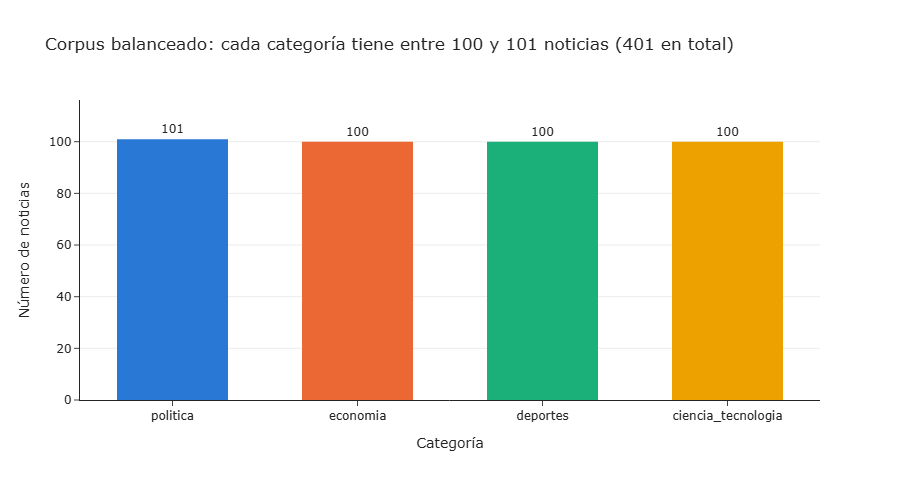

In [11]:
conteo = df["etiqueta"].value_counts().reindex(ORDEN_CATEGORIAS).rename_axis("etiqueta").reset_index(name="noticias")
mn, mx = conteo["noticias"].min(), conteo["noticias"].max()
if mx / mn <= 1.15:
    titulo = f"Corpus balanceado: cada categoría tiene entre {mn} y {mx} noticias ({len(df)} en total)"
else:
    top = conteo.loc[conteo["noticias"].idxmax(), "etiqueta"]
    titulo = f"Corpus desbalanceado: {top} concentra {mx} noticias frente a {mn} de la menor"

fig = px.bar(conteo, x="etiqueta", y="noticias", text="noticias",
             color="etiqueta", color_discrete_map=COLORES,
             labels={"etiqueta": "Categoría", "noticias": "Número de noticias"}, title=titulo)
fig.update_traces(textposition="outside", marker_line_width=0, width=0.6, cliponaxis=False)
fig.update_layout(showlegend=False, width=900, height=480, title_font_size=17,
                  yaxis=dict(range=[0, mx * 1.15], showgrid=True, gridcolor="#ececec"))
fig.show()

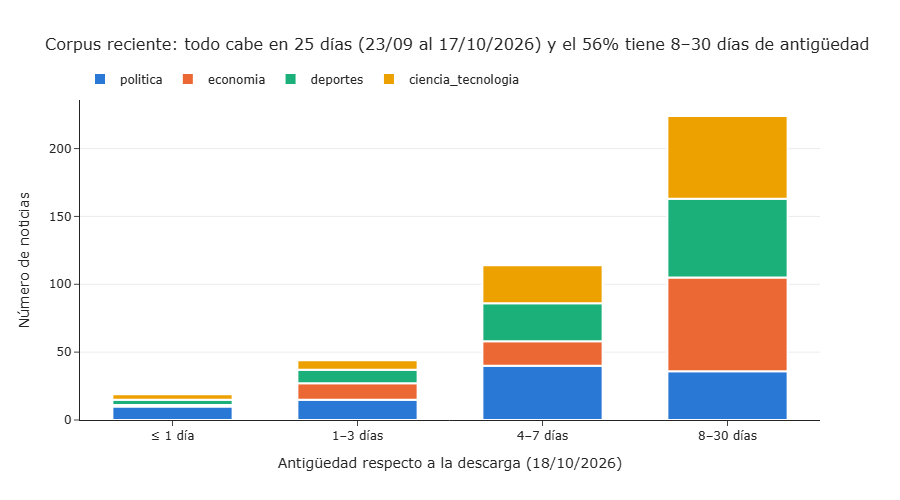

etiqueta,politica,economia,deportes,ciencia_tecnologia,Total
rango_fecha,,,,,
≤ 1 día,10,1,4,4,19
1–3 días,15,12,10,7,44
4–7 días,40,18,28,28,114
8–30 días,36,69,58,61,224
Total,101,100,100,100,401


In [12]:
descarga = pd.Timestamp("2026-10-18", tz="America/Lima")
dias = (descarga - df["fecha_dt"]).dt.total_seconds() / 86400
cortes = [-1, 1, 3, 7, 30, 365, float("inf")]
rangos = ["≤ 1 día", "1–3 días", "4–7 días", "8–30 días", "1–12 meses", "Más de 1 año"]
# Se muestran solo los rangos que tienen noticias
df["rango_fecha"] = pd.cut(dias, bins=cortes, labels=rangos).cat.remove_unused_categories()
rangos = list(df["rango_fecha"].cat.categories)

tabla_rangos = (df.groupby(["rango_fecha", "etiqueta"], observed=False).size()
                  .rename("noticias").reset_index())
ini, fin = df["fecha_dt"].min(), df["fecha_dt"].max()
span = (fin.normalize() - ini.normalize()).days + 1
modal = df["rango_fecha"].value_counts().idxmax()
pct_modal = (df["rango_fecha"] == modal).mean() * 100
titulo = (f"Corpus reciente: todo cabe en {span} días ({ini:%d/%m} al {fin:%d/%m/%Y}) "
          f"y el {pct_modal:.0f}% tiene {modal} de antigüedad")

fig = px.bar(tabla_rangos, x="rango_fecha", y="noticias", color="etiqueta",
             category_orders={"rango_fecha": rangos, "etiqueta": ORDEN_CATEGORIAS},
             color_discrete_map=COLORES, title=titulo,
             labels={"rango_fecha": "Antigüedad respecto a la descarga (18/10/2026)",
                     "noticias": "Número de noticias", "etiqueta": "Categoría"})
fig.update_traces(marker_line_color="white", marker_line_width=2)
fig.update_layout(width=900, height=500, title_font_size=16, bargap=0.35,
                  yaxis=dict(showgrid=True, gridcolor="#ececec"),
                  legend=dict(orientation="h", y=1.02, yanchor="bottom", x=0, title_text=""))
fig.show()

pd.crosstab(df["rango_fecha"], df["etiqueta"], margins=True, margins_name="Total")[ORDEN_CATEGORIAS + ["Total"]]

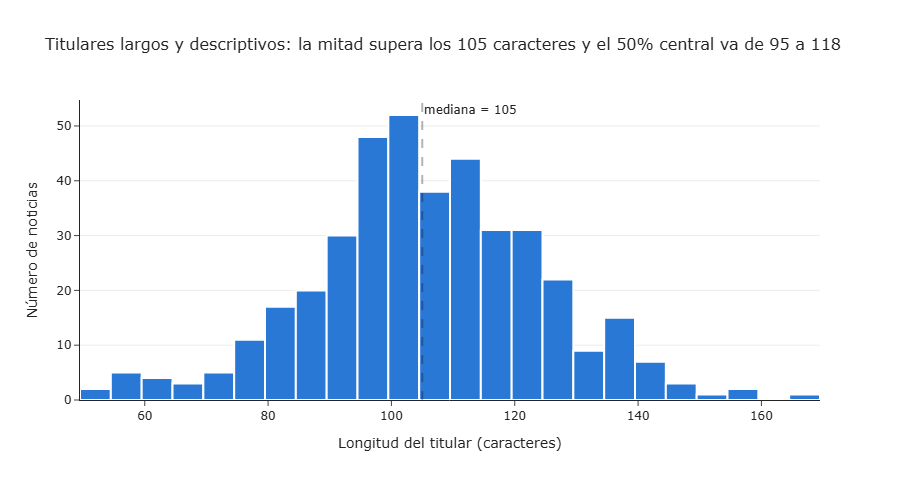

,count,mean,50%,min,max
etiqueta,,,,,
politica,101.0,97.8,103.0,50.0,138.0
economia,100.0,97.8,98.0,60.0,131.0
deportes,100.0,105.6,105.0,57.0,148.0
ciencia_tecnologia,100.0,122.1,122.0,92.0,165.0


In [13]:
df["largo_titular"] = df["titular"].str.len()
mediana = df["largo_titular"].median()
q1, q3 = df["largo_titular"].quantile([0.25, 0.75])
titulo = (f"Titulares largos y descriptivos: la mitad supera los {mediana:.0f} caracteres "
          f"y el 50% central va de {q1:.0f} a {q3:.0f}")

fig = px.histogram(df, x="largo_titular", nbins=30, title=titulo,
                   color_discrete_sequence=["#2a78d6"],
                   labels={"largo_titular": "Longitud del titular (caracteres)"})
fig.update_traces(marker_line_color="white", marker_line_width=2)
fig.add_vline(x=mediana, line_dash="dash", line_color="#0b0b0b", line_width=2,
              annotation_text=f"mediana = {mediana:.0f}", annotation_position="top right")
fig.update_layout(width=900, height=480, title_font_size=16, yaxis_title="Número de noticias",
                  yaxis=dict(showgrid=True, gridcolor="#ececec"))
fig.show()

df.groupby("etiqueta")["largo_titular"].describe()[["count", "mean", "50%", "min", "max"]].round(1).reindex(ORDEN_CATEGORIAS)

## 5. Validación: titulares más largos y más cortos

Sirve para detectar titulares truncados, basura de HTML o notas que no son noticias (p. ej. tablas o en vivos).

In [14]:
cols = ["largo_titular", "etiqueta", "titular", "url"]
with pd.option_context("display.max_colwidth", 250):
    print("5 titulares MÁS LARGOS")
    display(df.nlargest(5, "largo_titular")[cols].reset_index(drop=True))
    print("5 titulares MÁS CORTOS")
    display(df.nsmallest(5, "largo_titular")[cols].reset_index(drop=True))

5 titulares MÁS LARGOS


,largo_titular,etiqueta,titular,url
0,165,ciencia_tecnologia,Japón se equivocó y pagó las consecuencias: envió a la criatura equivocada para erradicar las serpientes y provocó un desastre que tardó casi 50 años en solucionarse,https://larepublica.pe/ciencia/2026/09/27/japon-se-equivoco-y-pago-las-consecuencias-envio-a-la-criatura-equivocada-para-erradicar-las-serpientes-y-provoco-un-desastre-que-tardo-casi-50-anos-en-solucionarse-2571669
1,158,ciencia_tecnologia,"La humanidad roza sus límites: la población mundial alcanzaría los 12.400 millones en 2070, mientras científicos sugieren reducirla a 4.000 millones para 2200",https://larepublica.pe/ciencia/2026/09/30/la-humanidad-roza-sus-limites-la-poblacion-mundial-alcanzaria-los-12400-millones-en-2070-mientras-cientificos-sugieren-reducirla-a-4000-millones-para-2200-838170
2,157,ciencia_tecnologia,"Retiraron cabras de una isla cerca de Venezuela para salvar su bosque, pero 15 años después científicos descubrieron que no se recuperó al 100% por una razón",https://larepublica.pe/ciencia/2026/09/25/retiraron-cabras-de-una-isla-cerca-de-america-latina-para-salvar-su-bosque-pero-15-anos-despues-cientificos-hallaron-un-resultado-inesperado-1374425
3,153,ciencia_tecnologia,Kenia diseña la primera motocicleta eléctrica de producción con más de 1 km de autonomía por minuto de carga: su batería resiste el agua y cuenta con GPS,https://larepublica.pe/ciencia/2026/10/02/la-moto-electrica-que-suma-mas-de-1-km-de-autonomia-por-minuto-de-carga-y-tiene-bateria-resistente-al-agua-con-gps-fue-presentada-en-kenia-199864
4,148,deportes,"Mia Shalit, arquera de Universitario, destaca el nivel de las cremas pese a derrota ante Palmeiras por Copa Libertadores Femenina: ""Estuvimos cerca""",https://larepublica.pe/deportes/2026/10/16/mia-shalit-arquera-de-universitario-destaca-el-nivel-de-las-cremas-pese-a-derrota-ante-palmeiras-por-copa-libertadores-femenina-estuvimos-cerca-600528


5 titulares MÁS CORTOS


,largo_titular,etiqueta,titular,url
0,50,politica,Fugó cabecilla de la banda que mató a “China Polo”,https://larepublica.pe/politica/2026/10/08/fugo-cabecilla-de-la-banda-que-mato-a-china-polo-adrian-azuaje-solis-adrian-solis-ruiz-susy-aponte-polo-hnews-767016
1,54,politica,Minería ilegal elevó 8 veces la demanda de combustible,https://larepublica.pe/politica/2026/10/10/mineria-ilegal-elevo-8-veces-la-demanda-de-combustible-mineria-ilegal-hnews-452480
2,56,politica,Vaticano informa que Papa León XIV tiene cáncer pulmonar,https://larepublica.pe/politica/2026/10/13/vaticano-informa-que-papa-leon-xiv-tiene-cancer-pulmonar-hnews-988546
3,57,deportes,¿Cuándo inicia la Liga Peruana de Vóley Femenina 2026-27?,https://larepublica.pe/deportes/2026/10/13/cuando-inicia-la-liga-peruana-de-voley-femenino-202627-423826
4,58,politica,Gobierno plantea regulación de armas de fuego de uso civil,https://larepublica.pe/politica/2026/10/11/gobierno-plantea-regulacion-de-armas-de-fuego-de-uso-civil-inseguridad-ciudadana-hnews-498938


## 6. Exportación a `datos/noticias.csv`

In [15]:
COLUMNAS = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
final = df[COLUMNAS].copy()
assert final["url"].is_unique and final["titular"].ne("").all()
assert set(final["etiqueta"]) == set(ORDEN_CATEGORIAS)
assert len(final) >= 350, "Se requieren al menos 350 noticias"

final.to_csv(DATOS / "noticias.csv", index=False, encoding="utf-8")
print("Guardado:", DATOS / "noticias.csv")
print("df.shape =", final.shape)
final.head(5)

Guardado: datos\noticias.csv
df.shape = (401, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Alianza Lima se hizo fuerte en Matute: venció 3-1 a Atlético Grau y se mantiene en la lucha por el Torneo Clausura d...,El equipo dirigido por Pablo Guede sumó una nueva victoria en el Torneo Clausura y superó a Atlético Grau en el esta...,La República,deportes,https://larepublica.pe/deportes/2026/10/17/en-vivo-alianza-lima-vs-atletico-grau-a-que-hora-y-donde-ver-partido-de-h...,2026-10-17 22:45,deportes
1,Tabla de posiciones Torneo Clausura y Acumulado de la Liga 1 2026: resultados de los partidos de la fecha 12,"Revisa cómo marcha el Torneo Clausura, qué equipos se encuentran liderando la tabla de posiciones y qué clubes pelea...",La República,deportes,https://larepublica.pe/deportes/2026/10/16/tabla-de-posiciones-torneo-clausura-y-acumulado-de-la-liga-1-2026-actuali...,2026-10-17 22:32,deportes
2,¡Rugieron Las Pumas! Universitario venció 3-0 a Deportivo Soan y empieza con pie derecho la Liga Peruana de Vóley 20...,"Con una gran actuación de Catherine Flood, Universitario venció 3-0 a Deportivo Soan por la fecha 1 de la Liga Perua...",La República,deportes,https://larepublica.pe/deportes/2026/10/17/en-vivo-universitario-vs-deportivo-soan-a-que-hora-y-donde-ver-partido-de...,2026-10-17 19:44,deportes
3,Científicos demuestran que un breve contacto físico entre corales sanos y blanqueados puede ayudarles a restaurar el...,"El estrés térmico expulsa las algas que dan alimento y color a los corales, dejándolos debilitados y en riesgo de mo...",La República,ciencia,https://larepublica.pe/ciencia/2026/10/17/cientificos-demuestran-que-un-breve-contacto-fisico-entre-corales-sanos-y-...,2026-10-17 18:43,ciencia_tecnologia
4,El Reino Unido pondrá en marcha la primera garra robótica del mundo para recolectar la basura espacial que rodea a l...,"La iniciativa responde al creciente problema de miles de desechos espaciales, lo que representa un riesgo significat...",La República,ciencia,https://larepublica.pe/ciencia/2026/10/17/el-reino-unido-pondra-en-marcha-la-primera-garra-robotica-del-mundo-para-r...,2026-10-17 18:01,ciencia_tecnologia


## 7. Conclusiones y limitaciones

**Resultado:** `datos/noticias.csv` con **401 noticias reales** de La República y 7 columnas, balanceadas por categoría
(politica 101, economia 100, deportes 100, ciencia_tecnologia 100), publicadas entre el 23/09 y el 17/10/2026.

**Proceso:**
- Se hicieron 419 solicitudes en ~16 min: 411 respuestas 200, 7 respuestas 404 (enlaces internos rotos, que se omitieron) y 1 respuesta 410 (`rss/tecnologia.xml`, feed retirado). No hubo bloqueos por *rate limit* ni hizo falta reintentar.
- De 638 registros crudos se descartaron 237: **87 duplicados por URL** (la misma nota aparecía en el RSS de su sección, en `home.xml` y en el recorrido), **150 de secciones fuera de alcance** (sociedad, espectáculos, mundo, etc., casi todas del RSS `home.xml`) y **0 titulares vacíos**.

**Hallazgos del EDA:**
- Las clases quedan balanceadas por diseño (cuota de 100 por grupo), lo que evita sesgar al clasificador de la Parte 2.
- Los titulares son largos (mediana ≈ 105 caracteres). Los de `ciencia_tecnologia` son los más extensos (mediana ≈ 122), porque son explicativos (*"Japón se equivocó y pagó las consecuencias: ..."*). Los de política son los más cortos y secos (*"Fugó cabecilla de la banda que mató a 'China Polo'"*).
- `economia`, `deportes` y `ciencia_tecnologia` se concentran en el rango de 8 a 30 días, mientras que `politica` es más reciente porque esa sección publica más notas por día.

**Limitaciones:**
- **Etiquetas por sección, no por contenido:** la etiqueta hereda la sección del medio. Por ejemplo, en `politica` aparecen notas de la edición impresa (`hnews`) como *"Vaticano informa que Papa León XIV tiene cáncer pulmonar"*. Esto introduce algo de ruido en las etiquetas.
- **`ciencia_tecnologia` proviene en la práctica de `/ciencia`:** el recorrido (de lo más reciente a lo más antiguo) completó la cuota con notas de `/ciencia` antes de llegar a URLs `/tecnologia`. Aun así, `/ciencia` incluye notas de tecnología (por ejemplo, la moto eléctrica de Kenia).
- **Sin paginación:** al respetar robots.txt no se puede retroceder en el tiempo de forma ordenada, así que el periodo cubierto depende de los enlaces internos de los artículos.
- `bajada` proviene de la descripción del RSS o de `og:description`, que el medio a veces redacta pensando en SEO.